# Laborator 6 - Inferenta bayesiana

$\lambda$ = numarul mediu de apeluri pe ora. Date: $n = 10$ ore, $\sum x_i = 180$ apeluri.

- verosimilitate: $X_i \mid \lambda \sim \text{Poisson}(\lambda)$
- prior: $\lambda \sim \text{Gamma}(\alpha, \beta)$

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import arviz as az

n = 10
total = 180

## Alegerea priorului
Nu stim exact rata, doar ca variaza, asa ca iau un prior larg: $\alpha = 2,\ \beta = 0.1$.

Media e $\alpha/\beta = 20$ (valoare plauzibila), iar dispersia $\alpha/\beta^2 = 200$ e mare, deci priorul conteaza putin si decid datele.

In [2]:
alpha, beta = 2, 0.1

## Posteriorul
$$p(\lambda \mid x) \propto p(x \mid \lambda)\,p(\lambda) \propto \prod_{i=1}^{n} e^{-\lambda}\lambda^{x_i} \cdot \lambda^{\alpha-1}e^{-\beta\lambda} = \lambda^{\alpha + \sum x_i - 1}\,e^{-(\beta + n)\lambda}$$

Are forma unei Gamma, deci:
$$\lambda \mid x \sim \text{Gamma}(\alpha + \textstyle\sum x_i,\ \beta + n) = \text{Gamma}(182,\ 10.1)$$

- media: $\dfrac{182}{10.1} \approx 18.02$
- modul (cea mai probabila valoare): $\dfrac{182 - 1}{10.1} \approx 17.92$

In [3]:
a_post = alpha + total
b_post = beta + n

print("posterior: Gamma(", a_post, ",", b_post, ")")
print("media:", a_post / b_post)
print("modul:", (a_post - 1) / b_post)

posterior: Gamma( 182 , 10.1 )
media: 18.01980198019802
modul: 17.92079207920792


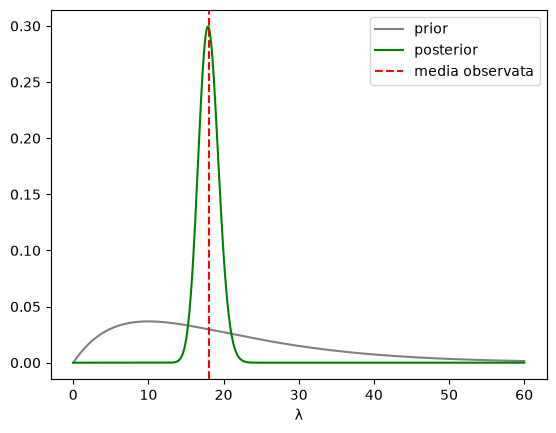

In [4]:
# scipy foloseste scale = 1/beta
prior = stats.gamma(a=alpha, scale=1/beta)
post = stats.gamma(a=a_post, scale=1/b_post)

x = np.linspace(0, 60, 1000)
plt.plot(x, prior.pdf(x), label='prior', color='gray')
plt.plot(x, post.pdf(x), label='posterior', color='green')
plt.axvline(18, color='red', linestyle='--', label='media observata')
plt.xlabel('λ')
plt.legend()
plt.show()

Priorul e aproape plat, iar posteriorul se strange in jurul lui 18, deci datele domina.

## HDI 94% si modul

HDI 94%: [15.55751683 20.55388957]


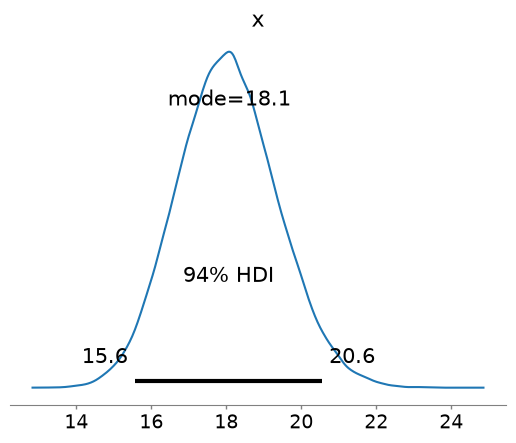

In [5]:
esantion = post.rvs(size=100000, random_state=12)

print("HDI 94%:", az.hdi(esantion, hdi_prob=0.94))

az.plot_posterior(esantion, hdi_prob=0.94, point_estimate='mode', round_to=3)
plt.show()

## Concluzie
- posterior: $\text{Gamma}(182,\ 10.1)$
- cea mai probabila valoare: $\lambda \approx 17.92$ apeluri/ora (ArviZ da ~18.1 pentru ca estimeaza modul din esantion)
- HDI 94%: aproximativ $[15.5,\ 20.5]$, adica suntem 94% siguri ca rata reala e intre 15.5 si 20.5 apeluri pe ora